# 04 — Additional Baselines, Class Imbalance & Tuning (Package B — Dulsara)
EC5203 Group 07 — Multi-Class Chronic Disease Prediction

Package B tasks (revised work allocation):
1. Decision Tree and SVM baselines (`src/models_baseline_b.py`, first results in `03b_feature_selection_baseline_b.ipynb`)
2. **Bounded hyperparameter tuning with cross-validation** on training data → `dulsara_cv_tuning.csv`
3. **Class-weighted vs unweighted**, plus training-only **random oversampling** and **SMOTE** → `dulsara_imbalance_comparison.csv`
4. Per-class confusion patterns, runtime, seeds, chosen hyperparameters, limitations

Common protocol: `prepare_dataset()` → `split_three_ways()` (70/15/15, seed 42) → `build_pipeline()` (engineered features).
Primary metric: **macro F1**. Resampling sits inside an imbalanced-learn Pipeline, so it only touches training data / CV training folds.
**The test set is not used.**

In [1]:
from pathlib import Path
import sys, json, platform, time

PROJECT_ROOT = Path.cwd().resolve()
while not (PROJECT_ROOT / "src").is_dir():
    if PROJECT_ROOT.parent == PROJECT_ROOT:
        raise FileNotFoundError("Project src folder was not found.")
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn, imblearn
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import ConfusionMatrixDisplay

from src.preprocessing import prepare_dataset
from src.three_way_split import split_three_ways
from src.imbalance_experiments import (build_imbalance_pipeline, tune_with_cv,
                                       evaluate_on_validation, STRATEGIES, RARE_CLASSES)

RANDOM_STATE = 42
USE_ENGINEERING = True       # engineered features gave the best validation results so far
SVM_TRAIN_LIMIT = 10_000     # RBF SVM is O(n^2) in training rows; documented simplification
CV_FOLDS = 3                 # bounded tuning budget

TAB_DIR = PROJECT_ROOT / "results" / "tables";  TAB_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR = PROJECT_ROOT / "results" / "figures"; FIG_DIR.mkdir(parents=True, exist_ok=True)
print("sklearn", sklearn.__version__, "| imblearn", imblearn.__version__, "| python", platform.python_version())

sklearn 1.9.1 | imblearn 0.14.2 | python 3.14.9


## 1. Data and the approved 70/15/15 split

In [2]:
X, y = prepare_dataset(PROJECT_ROOT / "data" / "raw" / "Data Warehouse Multiclass.csv")
X_train, X_val, X_test, y_train, y_val, y_test = split_three_ways(X, y, random_state=RANDOM_STATE)
del X_test, y_test   # reserved for the final coordinated evaluation (Esandu)

groups_train = pd.util.hash_pandas_object(X_train, index=False)

# Select one group-aware fold close to 10k rows for the RBF SVM.
SVM_SUBSET_FOLDS = max(2, round(len(X_train) / SVM_TRAIN_LIMIT))
subset_cv = StratifiedGroupKFold(
    n_splits=SVM_SUBSET_FOLDS, shuffle=True, random_state=RANDOM_STATE
)
_, svm_subset_idx = next(subset_cv.split(X_train, y_train, groups_train))
X_svm = X_train.iloc[svm_subset_idx].copy()
y_svm = y_train.iloc[svm_subset_idx].copy()
groups_svm = groups_train.iloc[svm_subset_idx].copy()

expected_classes = set(y_train.unique())
svm_classes = set(y_svm.unique())
print("SVM subset rows:", len(X_svm), "| classes:", sorted(svm_classes))
assert len(expected_classes) == 8 and svm_classes == expected_classes, (
    f"SVM subset must contain all eight training classes; got {sorted(svm_classes)}"
)
print("Decision Tree training rows:", len(X_train), "| SVM training rows:", len(X_svm), "| validation:", len(X_val))

=== DATASET PREPARATION ===
Original shape: (280985, 39)
Predictor shape: (280985, 24)
Target shape: (280985,)
Exact duplicates: 2284
Target classes: 8

Class distribution:
sublabel
N           106884
HY           69806
DI_HY        66473
DI           31918
HT            2595
DI_HT         1398
HT_HY         1066
DI_HT_HY       845
Name: count, dtype: int64

=== DUPLICATE HANDLING ===
Original records: 280985
Exact duplicate records removed: 2284
Remaining records: 278701

=== 70/15/15 DATA SPLIT ===
Training: 195091 (70.00%)
Validation: 41806 (15.00%)
Testing: 41804 (15.00%)

=== CLASS DISTRIBUTION (%) ===
            Original  Training  Validation  Testing
__target__                                         
N              37.55     37.55       37.55    37.55
HY             25.04     25.04       25.04    25.04
DI_HY          23.85     23.85       23.85    23.85
DI             11.45     11.45       11.45    11.45
HT              0.93      0.93        0.93     0.93
DI_HT           0.50 

## 2. Bounded CV tuning — Decision Tree (full training set, class-weighted)
Grid: `max_depth` ∈ {8, 12, 16, 20} × `min_samples_leaf` ∈ {1, 20, 50} — 12 settings × 3 folds.

In [3]:
dt_grid = {"classifier__max_depth": [8, 12, 16, 20],
           "classifier__min_samples_leaf": [1, 20, 50]}
dt_search, dt_cv, dt_seconds = tune_with_cv(
    build_imbalance_pipeline(
        "decision_tree", X_train, "class_weight", USE_ENGINEERING
    ),
    dt_grid,
    X_train,
    y_train,
    groups_train,
    n_splits=CV_FOLDS,
    random_state=RANDOM_STATE,
    n_jobs=1
)

DT_BEST = {k.replace("classifier__", ""): v for k, v in dt_search.best_params_.items()}
print(f"Decision Tree tuning: {dt_seconds:.0f}s | best {DT_BEST} | CV macro F1 = {dt_search.best_score_:.4f}")
dt_cv.head(12)

Decision Tree tuning: 73s | best {'max_depth': 20, 'min_samples_leaf': 1} | CV macro F1 = 0.3758


,param_classifier__max_depth,param_classifier__min_samples_leaf,mean_test_macro_f1,std_test_macro_f1,mean_test_balanced_accuracy,mean_test_weighted_f1,mean_fit_time,rank_test_macro_f1
0,20,1,0.375791,0.001462,0.432434,0.674873,1.922682,1
1,16,1,0.374370,0.001093,0.487147,0.669123,1.676251,2
2,20,20,0.370022,0.000288,0.528679,0.656367,1.798570,3
3,16,20,0.369278,0.000863,0.536622,0.659556,1.625878,4
4,20,50,0.364726,0.000912,0.547006,0.648998,1.691910,5
5,16,50,0.364237,0.000710,0.549816,0.650867,1.573911,6
6,12,50,0.362436,0.001346,0.550497,0.651533,1.384464,7
7,12,1,0.361726,0.001215,0.531034,0.651470,1.439776,8
8,12,20,0.361579,0.002529,0.545413,0.649666,1.382852,9
9,8,1,0.360052,0.002279,0.563090,0.650270,1.096982,10


## 3. Bounded CV tuning — SVM (RBF, 10k stratified training subset, class-weighted)
Grid: `C` ∈ {0.3, 1, 3, 10} × `gamma` ∈ {"scale", 0.01, 0.1} — 12 settings × 3 folds.

In [4]:
svm_grid = {"classifier__C": [0.3, 1, 3, 10],
            "classifier__gamma": ["scale", 0.01, 0.1]}
svm_search, svm_cv, svm_seconds = tune_with_cv(
    build_imbalance_pipeline("svm", X_svm, "class_weight", USE_ENGINEERING),
    svm_grid, X_svm, y_svm, groups_svm, n_splits=CV_FOLDS, random_state=RANDOM_STATE)

SVM_BEST = {k.replace("classifier__", ""): v for k, v in svm_search.best_params_.items()}
print(f"SVM tuning: {svm_seconds:.0f}s | best {SVM_BEST} | CV macro F1 = {svm_search.best_score_:.4f}")
svm_cv.head(12)

SVM tuning: 12s | best {'C': 10, 'gamma': 'scale'} | CV macro F1 = 0.3582


,param_classifier__C,param_classifier__gamma,mean_test_macro_f1,std_test_macro_f1,mean_test_balanced_accuracy,mean_test_weighted_f1,mean_fit_time,rank_test_macro_f1
0,10.0,scale,0.358208,0.010855,0.408148,0.669118,1.019884,1
1,3.0,0.1,0.355290,0.007287,0.405409,0.679828,1.469437,2
2,3.0,scale,0.353304,0.005564,0.416919,0.662192,0.937761,3
3,10.0,0.1,0.351092,0.009930,0.386492,0.680574,1.308144,4
4,1.0,0.1,0.349117,0.015444,0.411500,0.668497,1.403868,5
5,10.0,0.01,0.345874,0.008825,0.423112,0.648588,0.834615,6
6,1.0,scale,0.345859,0.008972,0.421436,0.653737,1.067598,7
7,0.3,scale,0.340541,0.010094,0.437416,0.648265,1.432007,8
8,3.0,0.01,0.339785,0.010896,0.427452,0.645146,0.930627,9
9,1.0,0.01,0.333364,0.004732,0.425371,0.640607,1.162225,10


## 4. Bounded CV tuning — Random Forest (full training set, class-weighted)

In [5]:
rf_grid = {
    "classifier__n_estimators": [100, 200],
    "classifier__max_depth": [12, 20],
    "classifier__min_samples_leaf": [5, 20],
    "classifier__max_features": ["sqrt"],
}

rf_search, rf_cv, rf_seconds = tune_with_cv(
    build_imbalance_pipeline(
        "random_forest",
        X_train,
        "class_weight",
        USE_ENGINEERING
    ),
    rf_grid,
    X_train,
    y_train,
    groups_train,
    n_splits=CV_FOLDS,
    random_state=RANDOM_STATE,
    n_jobs=1
)

RF_BEST = {
    k.replace("classifier__", ""): v
    for k, v in rf_search.best_params_.items()
}

print(
    f"Random Forest tuning: {rf_seconds:.0f}s | "
    f"best {RF_BEST} | "
    f"CV macro F1 = {rf_search.best_score_:.4f}"
)

rf_cv.head(12)

Random Forest tuning: 353s | best {'max_depth': 20, 'max_features': 'sqrt', 'min_samples_leaf': 5, 'n_estimators': 100} | CV macro F1 = 0.3851


,param_classifier__max_depth,param_classifier__max_features,param_classifier__min_samples_leaf,param_classifier__n_estimators,mean_test_macro_f1,std_test_macro_f1,mean_test_balanced_accuracy,mean_test_weighted_f1,mean_fit_time,rank_test_macro_f1
0,20,sqrt,5,100,0.385074,0.001959,0.561878,0.686096,10.212630,1
1,20,sqrt,5,200,0.383965,0.001741,0.564306,0.685290,19.809222,2
2,20,sqrt,20,200,0.369982,0.002414,0.581619,0.669520,17.651653,3
3,20,sqrt,20,100,0.369795,0.001240,0.577623,0.669949,9.070885,4
4,12,sqrt,5,100,0.366974,0.001750,0.586321,0.655872,8.166347,5
5,12,sqrt,5,200,0.366217,0.001702,0.586578,0.655457,15.701006,6
6,12,sqrt,20,200,0.363640,0.001485,0.589099,0.653849,15.279845,7
7,12,sqrt,20,100,0.363455,0.002618,0.586217,0.653834,7.875633,8


In [6]:
dt_cv.insert(0, "Model", "Decision Tree")
svm_cv.insert(0, "Model", "SVM (RBF)")
rf_cv.insert(0, "Model", "Random Forest")

cv_tuning = pd.concat(
    [dt_cv, svm_cv, rf_cv],
    ignore_index=True
)

cv_tuning.to_csv(
    TAB_DIR / "dulsara_cv_tuning.csv",
    index=False
)

print("Saved dulsara_cv_tuning.csv:", cv_tuning.shape)

cv_tuning

Saved dulsara_cv_tuning.csv: (32, 13)


,Model,param_classifier__max_depth,param_classifier__min_samples_leaf,mean_test_macro_f1,std_test_macro_f1,mean_test_balanced_accuracy,mean_test_weighted_f1,mean_fit_time,rank_test_macro_f1,param_classifier__C,param_classifier__gamma,param_classifier__max_features,param_classifier__n_estimators
0,Decision Tree,20.0,1.0,0.375791,0.001462,0.432434,0.674873,1.922682,1,NaN,NaN,NaN,NaN
1,Decision Tree,16.0,1.0,0.374370,0.001093,0.487147,0.669123,1.676251,2,NaN,NaN,NaN,NaN
2,Decision Tree,20.0,20.0,0.370022,0.000288,0.528679,0.656367,1.798570,3,NaN,NaN,NaN,NaN
3,Decision Tree,16.0,20.0,0.369278,0.000863,0.536622,0.659556,1.625878,4,NaN,NaN,NaN,NaN
4,Decision Tree,20.0,50.0,0.364726,0.000912,0.547006,0.648998,1.691910,5,NaN,NaN,NaN,NaN
5,Decision Tree,16.0,50.0,0.364237,0.000710,0.549816,0.650867,1.573911,6,NaN,NaN,NaN,NaN
6,Decision Tree,12.0,50.0,0.362436,0.001346,0.550497,0.651533,1.384464,7,NaN,NaN,NaN,NaN
7,Decision Tree,12.0,1.0,0.361726,0.001215,0.531034,0.651470,1.439776,8,NaN,NaN,NaN,NaN
8,Decision Tree,12.0,20.0,0.361579,0.002529,0.545413,0.649666,1.382852,9,NaN,NaN,NaN,NaN
9,Decision Tree,8.0,1.0,0.360052,0.002279,0.563090,0.650270,1.096982,10,NaN,NaN,NaN,NaN


## 4. Class-imbalance comparison on the validation set (tuned hyperparameters)
Strategies: `unweighted`, `class_weight="balanced"`, `random_oversample` (training only), `smote` (training only).

In [11]:
rows, reports, preds = [], [], {}
for strategy in STRATEGIES:
    for model_key, name, Xtr, ytr, params in [
        ("decision_tree", "Decision Tree", X_train, y_train, DT_BEST),
        ("svm", "SVM (RBF)", X_svm, y_svm, SVM_BEST),
        ("random_forest", "Random Forest", X_train, y_train, RF_BEST),
    ]:
        pipe = build_imbalance_pipeline(model_key, Xtr, strategy, USE_ENGINEERING, params)
        row, rep, pred = evaluate_on_validation(pipe, Xtr, ytr, X_val, y_val, name, strategy)
        rows.append(row); reports.append(rep); preds[(name, strategy)] = pred
        print(f"{name:14s} {strategy:18s} macroF1={row['Macro_F1']:.4f} "
              f"balAcc={row['Balanced_Accuracy']:.4f} rareRecall={row['Rare_Class_Mean_Recall']:.4f} ({row['Fit_Seconds']}s)")

imbalance = pd.DataFrame(rows).sort_values(["Model", "Macro_F1"], ascending=[True, False]).reset_index(drop=True)
imbalance.to_csv(TAB_DIR / "dulsara_imbalance_comparison.csv", index=False)
pd.concat(reports).to_csv(TAB_DIR / "dulsara_class_wise_validation_metrics.csv")
imbalance

Decision Tree  unweighted         macroF1=0.3652 balAcc=0.3698 rareRecall=0.0609 (2.9s)
SVM (RBF)      unweighted         macroF1=0.3388 balAcc=0.3367 rareRecall=0.0170 (1.3s)
Random Forest  unweighted         macroF1=0.3441 balAcc=0.3552 rareRecall=0.0024 (21.0s)
Decision Tree  class_weight       macroF1=0.3793 balAcc=0.4564 rareRecall=0.2858 (2.9s)
SVM (RBF)      class_weight       macroF1=0.3591 balAcc=0.4059 rareRecall=0.1892 (1.2s)
Random Forest  class_weight       macroF1=0.3789 balAcc=0.5514 rareRecall=0.4817 (15.5s)
Decision Tree  random_oversample  macroF1=0.3765 balAcc=0.4610 rareRecall=0.3069 (6.1s)
SVM (RBF)      random_oversample  macroF1=0.3561 balAcc=0.4048 rareRecall=0.1949 (3.1s)
Random Forest  random_oversample  macroF1=0.3942 balAcc=0.5192 rareRecall=0.3939 (54.2s)
Decision Tree  smote              macroF1=0.3802 balAcc=0.4504 rareRecall=0.2754 (14.1s)
SVM (RBF)      smote              macroF1=0.3568 balAcc=0.3967 rareRecall=0.1734 (3.4s)
Random Forest  smote        

,Model,Strategy,Training_Rows,Accuracy,Macro_F1,Weighted_F1,Balanced_Accuracy,Rare_Class_Mean_Recall,Fit_Seconds,Recall_HT,Recall_HT_HY,Recall_DI_HT,Recall_DI_HT_HY
0,Decision Tree,smote,195091,0.661651,0.380231,0.678851,0.450445,0.275406,14.1,0.360825,0.23125,0.320574,0.188976
1,Decision Tree,class_weight,195091,0.663087,0.379310,0.680635,0.456375,0.285840,2.9,0.350515,0.20625,0.311005,0.275591
2,Decision Tree,random_oversample,195091,0.647395,0.376522,0.667992,0.460969,0.306908,6.1,0.404639,0.19375,0.196172,0.433071
3,Decision Tree,unweighted,195091,0.740277,0.365152,0.717967,0.369813,0.060883,2.9,0.048969,0.04375,0.095694,0.055118
4,Random Forest,random_oversample,195091,0.701957,0.394203,0.700192,0.519228,0.393936,54.2,0.623711,0.25000,0.473684,0.228346
5,Random Forest,smote,195091,0.697723,0.387256,0.693967,0.533368,0.430532,109.0,0.590206,0.31875,0.545455,0.267717
6,Random Forest,class_weight,195091,0.685835,0.378889,0.684908,0.551363,0.481651,15.5,0.623711,0.31250,0.612440,0.377953
7,Random Forest,unweighted,195091,0.765608,0.344148,0.737686,0.355197,0.002392,21.0,0.000000,0.00000,0.009569,0.000000
8,SVM (RBF),class_weight,9755,0.645649,0.359091,0.667506,0.405871,0.189203,1.2,0.394330,0.09375,0.205742,0.062992
9,SVM (RBF),smote,9755,0.651844,0.356800,0.670242,0.396663,0.173399,3.4,0.360825,0.07500,0.210526,0.047244


In [13]:
print("Total experiments:", len(imbalance))

print("\nExperiments per model:")
print(imbalance.groupby("Model").size())

print("\nRandom Forest results:")
display(
    imbalance[imbalance["Model"] == "Random Forest"][
        [
            "Strategy",
            "Accuracy",
            "Macro_F1",
            "Weighted_F1",
            "Balanced_Accuracy",
            "Rare_Class_Mean_Recall",
            "Fit_Seconds"
        ]
    ].sort_values("Macro_F1", ascending=False)
)

Total experiments: 12

Experiments per model:
Model
Decision Tree    4
Random Forest    4
SVM (RBF)        4
dtype: int64

Random Forest results:


,Strategy,Accuracy,Macro_F1,Weighted_F1,Balanced_Accuracy,Rare_Class_Mean_Recall,Fit_Seconds
4,random_oversample,0.701957,0.394203,0.700192,0.519228,0.393936,54.2
5,smote,0.697723,0.387256,0.693967,0.533368,0.430532,109.0
6,class_weight,0.685835,0.378889,0.684908,0.551363,0.481651,15.5
7,unweighted,0.765608,0.344148,0.737686,0.355197,0.002392,21.0


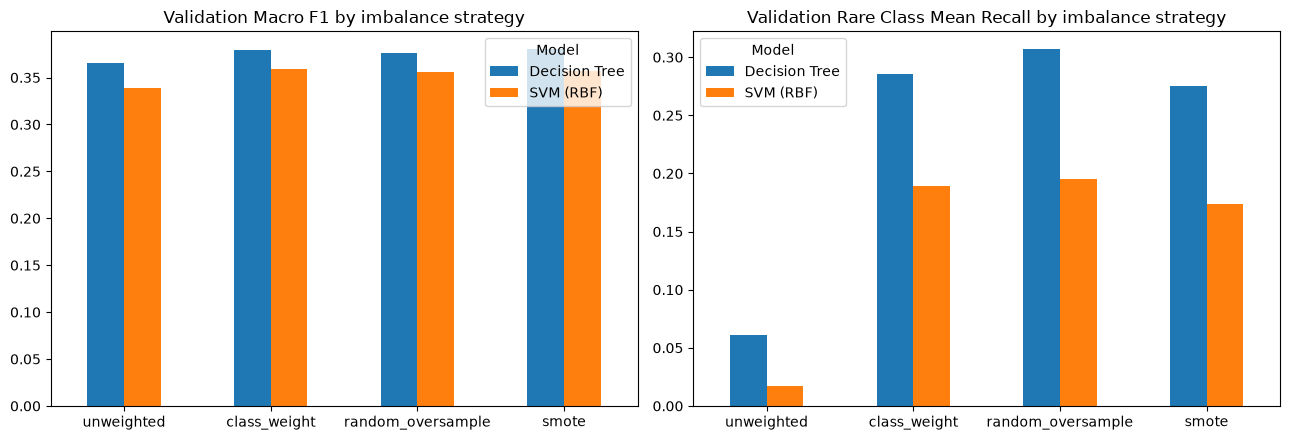

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, metric in zip(axes, ["Macro_F1", "Rare_Class_Mean_Recall"]):
    imbalance.pivot(index="Strategy", columns="Model", values=metric).loc[STRATEGIES].plot.bar(ax=ax, rot=0)
    ax.set_title(f"Validation {metric.replace('_', ' ')} by imbalance strategy"); ax.set_xlabel("")
plt.tight_layout(); plt.savefig(FIG_DIR / "04_dulsara_imbalance_comparison.png", dpi=150); plt.show()

## 5. Per-class confusion patterns — best strategy per model family (row-normalised)

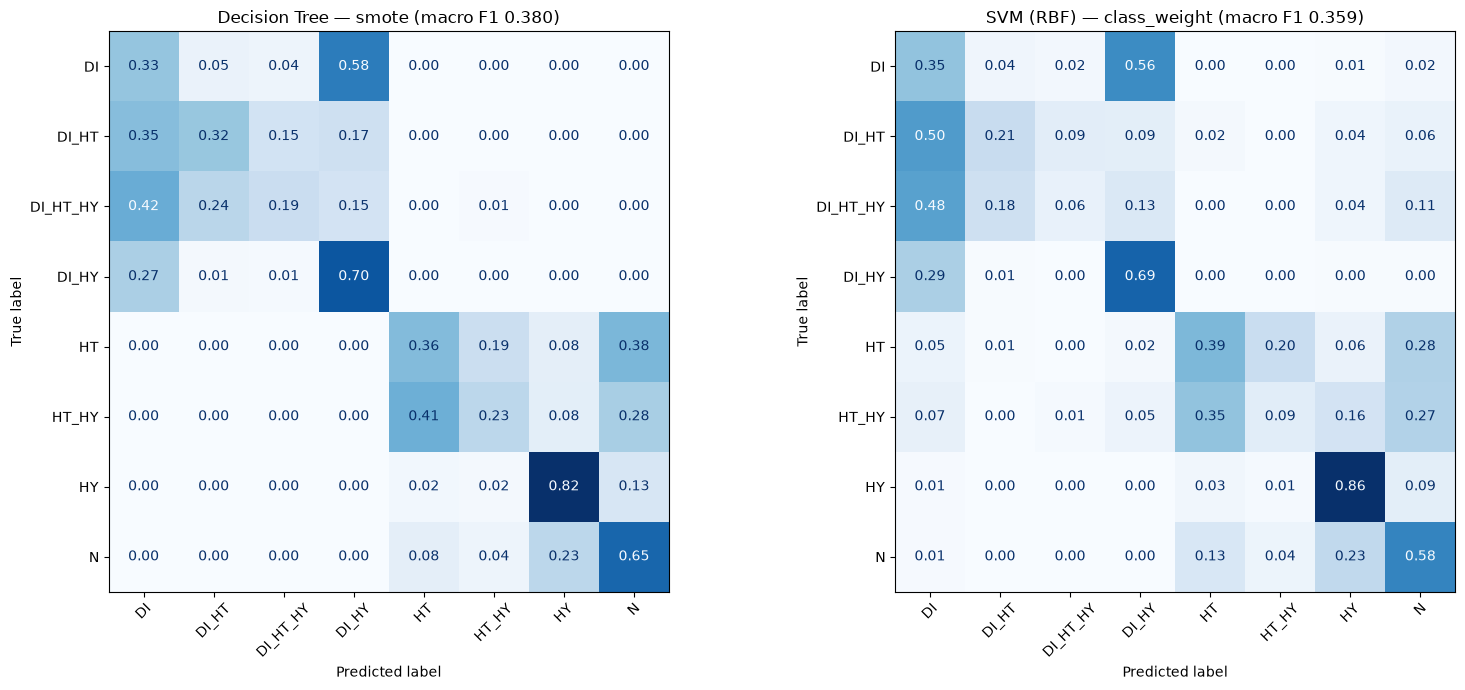

,Model,Strategy,Training_Rows,Accuracy,Macro_F1,Weighted_F1,Balanced_Accuracy,Rare_Class_Mean_Recall,Fit_Seconds,Recall_HT,Recall_HT_HY,Recall_DI_HT,Recall_DI_HT_HY
0,Decision Tree,smote,195091,0.661651,0.380231,0.678851,0.450445,0.275406,14.2,0.360825,0.23125,0.320574,0.188976
4,SVM (RBF),class_weight,9755,0.645649,0.359091,0.667506,0.405871,0.189203,1.2,0.394330,0.09375,0.205742,0.062992


In [9]:
best_per_model = imbalance.loc[imbalance.groupby("Model")["Macro_F1"].idxmax()]
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
for ax, (_, r) in zip(axes, best_per_model.iterrows()):
    ConfusionMatrixDisplay.from_predictions(y_val, preds[(r["Model"], r["Strategy"])], ax=ax,
                                            normalize="true", values_format=".2f",
                                            xticks_rotation=45, cmap="Blues", colorbar=False)
    ax.set_title(f"{r['Model']} — {r['Strategy']} (macro F1 {r['Macro_F1']:.3f})")
plt.tight_layout(); plt.savefig(FIG_DIR / "04_dulsara_confusion_matrices.png", dpi=150); plt.show()
best_per_model

In [18]:
rf_class_weight = build_imbalance_pipeline(
    "random_forest",
    X_train,
    "class_weight",
    USE_ENGINEERING,
    RF_BEST
)

rf_class_weight.fit(X_train, y_train)

print("Random Forest fitted successfully!")

Random Forest fitted successfully!


In [19]:
# Extract transformed feature names
preprocessor = rf_class_weight.named_steps["preprocessing"]

feature_names = preprocessor.get_feature_names_out()

# Extract Random Forest importance scores
importance_scores = (
    rf_class_weight.named_steps["classifier"].feature_importances_
)

# Create a sorted DataFrame
rf_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance_scores
}).sort_values("Importance", ascending=False)

# Display the top 20 features
display(rf_importance.head(20))

,Feature,Importance
2,numeric__HbA1c_level,0.218086
19,numeric__age_bmi_interaction,0.055468
0,numeric__age,0.051612
11,numeric__alcohol_intake,0.049975
9,numeric__systolic_bp,0.049512
14,numeric__hdl,0.048057
8,numeric__homocysteine_level,0.046093
3,numeric__glucose,0.044925
1,numeric__bmi,0.039904
10,numeric__diastolic_bp,0.038188


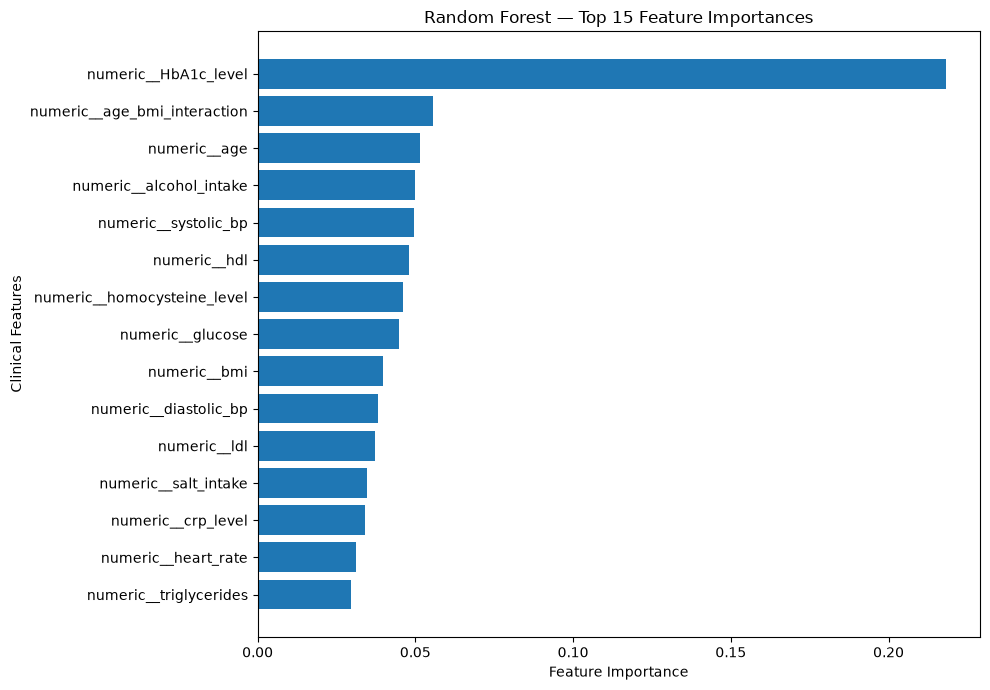

In [20]:
top_features = rf_importance.head(15).sort_values(
    "Importance",
    ascending=True
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Clinical Features")
plt.title("Random Forest — Top 15 Feature Importances")
plt.tight_layout()

plt.savefig(
    FIG_DIR / "04_random_forest_feature_importance.png",
    dpi=150
)

plt.show()

In [21]:
rf_importance.to_csv(
    TAB_DIR / "random_forest_feature_importance.csv",
    index=False
)

print("Feature importance saved successfully!")

Feature importance saved successfully!


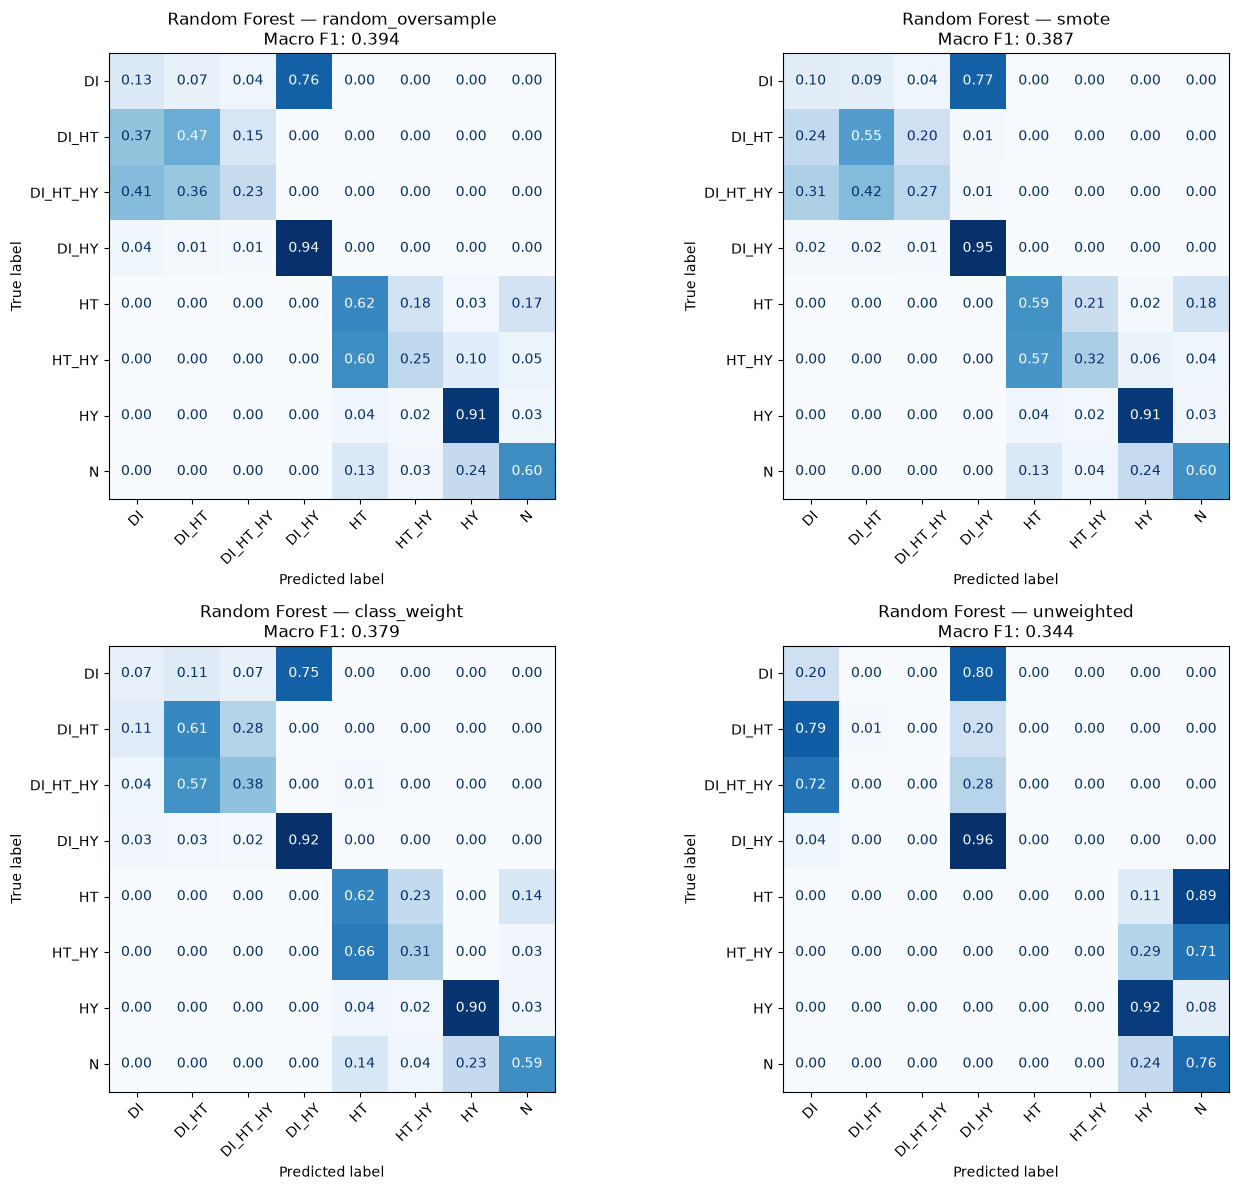

In [16]:
rf_results = imbalance[imbalance["Model"] == "Random Forest"]

fig, axes = plt.subplots(2, 2, figsize=(14, 12))

for ax, (_, r) in zip(axes.flat, rf_results.iterrows()):
    ConfusionMatrixDisplay.from_predictions(
        y_val,
        preds[(r["Model"], r["Strategy"])],
        ax=ax,
        normalize="true",
        values_format=".2f",
        xticks_rotation=45,
        cmap="Blues",
        colorbar=False
    )

    ax.set_title(
        f"Random Forest — {r['Strategy']}\n"
        f"Macro F1: {r['Macro_F1']:.3f}"
    )

plt.tight_layout()
plt.savefig(FIG_DIR / "04_random_forest_confusion_matrices.png", dpi=150)
plt.show()

## 6. Settings, runtime and chosen hyperparameters (reproducibility)

In [17]:
settings = {
    "random_state": RANDOM_STATE, "split": "70/15/15 grouped (src.three_way_split)",
    "use_engineering": USE_ENGINEERING, "cv_folds": CV_FOLDS, "svm_train_limit": SVM_TRAIN_LIMIT,
    "decision_tree": {"grid": dt_grid, "best": DT_BEST, "cv_macro_f1": dt_search.best_score_,
                      "tuning_seconds": round(dt_seconds, 1)},
    "svm_rbf": {"grid": svm_grid, "best": SVM_BEST, "cv_macro_f1": svm_search.best_score_,
                "tuning_seconds": round(svm_seconds, 1)},
    "random_forest": {"grid": rf_grid, "best": RF_BEST, "cv_macro_f1": rf_search.best_score_,
                      "tuning_seconds": round(rf_seconds, 1)},
                
    "best_validation": best_per_model[["Model", "Strategy", "Macro_F1", "Balanced_Accuracy"]].to_dict("records"),
    "test_set_used": False,
    "versions": {"python": platform.python_version(), "sklearn": sklearn.__version__,
                 "imblearn": imblearn.__version__, "pandas": pd.__version__, "numpy": np.__version__},
}
with open(TAB_DIR / "dulsara_settings.json", "w") as f:
    json.dump(settings, f, indent=2, default=str)
settings

{'random_state': 42,
 'split': '70/15/15 grouped (src.three_way_split)',
 'use_engineering': True,
 'cv_folds': 3,
 'svm_train_limit': 10000,
 'decision_tree': {'grid': {'classifier__max_depth': [8, 12, 16, 20],
   'classifier__min_samples_leaf': [1, 20, 50]},
  'best': {'max_depth': 20, 'min_samples_leaf': 1},
  'cv_macro_f1': np.float64(0.37579084981900673),
  'tuning_seconds': 73.1},
 'svm_rbf': {'grid': {'classifier__C': [0.3, 1, 3, 10],
   'classifier__gamma': ['scale', 0.01, 0.1]},
  'best': {'C': 10, 'gamma': 'scale'},
  'cv_macro_f1': np.float64(0.3582078050713731),
  'tuning_seconds': 12.1},
 'random_forest': {'grid': {'classifier__n_estimators': [100, 200],
   'classifier__max_depth': [12, 20],
   'classifier__min_samples_leaf': [5, 20],
   'classifier__max_features': ['sqrt']},
  'best': {'max_depth': 20,
   'max_features': 'sqrt',
   'min_samples_leaf': 5,
   'n_estimators': 100},
  'cv_macro_f1': np.float64(0.38507427923013826),
  'tuning_seconds': 352.7},
 'best_validatio

In [22]:
print("Random Forest output verification")

files_to_check = [
    TAB_DIR / "random_forest_feature_importance.csv",
    TAB_DIR / "dulsara_settings.json",
    TAB_DIR / "dulsara_imbalance_comparison.csv",
    FIG_DIR / "04_random_forest_feature_importance.png",
    FIG_DIR / "04_random_forest_confusion_matrices.png",
]

for file in files_to_check:
    print(
        f"{'FOUND' if file.exists() else 'MISSING'}: {file.name}"
    )

Random Forest output verification
FOUND: random_forest_feature_importance.csv
FOUND: dulsara_settings.json
FOUND: dulsara_imbalance_comparison.csv
FOUND: 04_random_forest_feature_importance.png
FOUND: 04_random_forest_confusion_matrices.png


In [23]:
print(settings["random_forest"])

print("\nBest validation results:")
display(best_per_model)

{'grid': {'classifier__n_estimators': [100, 200], 'classifier__max_depth': [12, 20], 'classifier__min_samples_leaf': [5, 20], 'classifier__max_features': ['sqrt']}, 'best': {'max_depth': 20, 'max_features': 'sqrt', 'min_samples_leaf': 5, 'n_estimators': 100}, 'cv_macro_f1': np.float64(0.38507427923013826), 'tuning_seconds': 352.7}

Best validation results:


,Model,Strategy,Training_Rows,Accuracy,Macro_F1,Weighted_F1,Balanced_Accuracy,Rare_Class_Mean_Recall,Fit_Seconds,Recall_HT,Recall_HT_HY,Recall_DI_HT,Recall_DI_HT_HY
0,Decision Tree,smote,195091,0.661651,0.380231,0.678851,0.450445,0.275406,14.2,0.360825,0.23125,0.320574,0.188976
4,SVM (RBF),class_weight,9755,0.645649,0.359091,0.667506,0.405871,0.189203,1.2,0.394330,0.09375,0.205742,0.062992


In [24]:
display(
    best_per_model[
        best_per_model["Model"] == "Random Forest"
    ].T
)

""
Model
Strategy
Training_Rows
Accuracy
Macro_F1
Weighted_F1
Balanced_Accuracy
Rare_Class_Mean_Recall
Fit_Seconds
Recall_HT


In [25]:
best_per_model = imbalance.loc[
    imbalance.groupby("Model")["Macro_F1"].idxmax()
].reset_index(drop=True)

print("Best strategy for each model:")
display(
    best_per_model[
        [
            "Model",
            "Strategy",
            "Macro_F1",
            "Balanced_Accuracy",
            "Rare_Class_Mean_Recall"
        ]
    ]
)

Best strategy for each model:


,Model,Strategy,Macro_F1,Balanced_Accuracy,Rare_Class_Mean_Recall
0,Decision Tree,smote,0.380231,0.450445,0.275406
1,Random Forest,random_oversample,0.394203,0.519228,0.393936
2,SVM (RBF),class_weight,0.359091,0.405871,0.189203


## 7. Interpretation and limitations
See `results/tables/dulsara_package_b_handoff.md` for the written summary of tuning, imbalance and class-wise findings.

Limitations: RBF SVM trained on a 10k stratified subset; bounded 3-fold grids; tuning was done with class weighting and the
tuned settings were reused for the other strategies; rare classes remain hard; clinical units unverified.